## Spectral analysis

A filter changes each frequency in its own way. `freqz` evaluates the response $H(e^{j\omega}) = B(e^{j\omega})/A(e^{j\omega})$ of the filter `b`, `a` around the upper unit circle. Here a 9-point moving average and a one-pole smoother, both low-pass: the moving average has zeros where whole periods fit in its window.

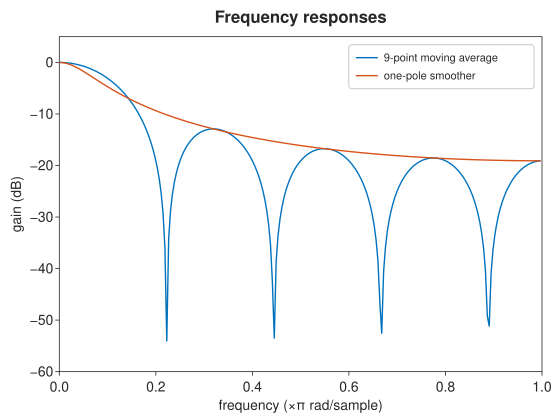

In [ ]:
[h1, w] = freqz(ones(1, 9) / 9, 1, 256);
h2 = freqz(0.2, [1, -0.8], 256);
plot(w/pi, 20*log10(abs(h1) + eps), w/pi, 20*log10(abs(h2)))
ylim([-60 5]), xlabel('frequency (\times\pi rad/sample)'), ylabel('gain (dB)')
legend('9-point moving average', 'one-pole smoother'), title('Frequency responses')

Windows taper a segment's ends so that its spectrum leaks less. The Hamming window does not reach zero; the Hann window does:

In [ ]:
fprintf('hamming(9): %s\n', mat2str(hamming(9)', 3))
fprintf('hann(9):    %s\n', mat2str(hann(9)', 3))

hamming(9): [0.08 0.215 0.54 0.865 1 0.865 0.54 0.215 0.08]


hann(9):    [0 0.146 0.5 0.854 1 0.854 0.5 0.146 0]


Welch's method estimates a power spectral density by averaging the periodograms of overlapping, windowed segments: by default 8 segments with 50% overlap and Hamming windows. Two tones at 60 Hz and 150 Hz in noise stand out clearly:

the strongest peak is at 60.5469 Hz


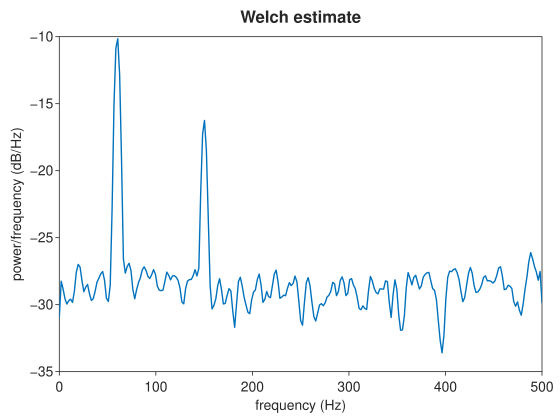

In [ ]:
rng(1);
fs = 1000; t = (0:2047)' / fs;
x = sin(2*pi*60*t) + 0.5*sin(2*pi*150*t) + 0.8*randn(size(t));
[pxx, f] = pwelch(x, 256, 128, 512, fs);
plot(f, 10*log10(pxx)), xlabel('frequency (Hz)'), ylabel('power/frequency (dB/Hz)'), title('Welch estimate')
[~, k] = max(pxx); fprintf('the strongest peak is at %g Hz\n', f(k))

A spectrogram shows how the spectrum changes with time: the short-time Fourier transform of windowed segments, one column per segment. In a chirp the frequency rises steadily; the frequency of the strongest bin in each segment follows it:

In [ ]:
fs = 1000; t = (0:1999) / fs;
c = cos(2*pi*(50*t + 100*t.^2));    % instantaneous frequency 50 + 200 t Hz
[s, f, tt] = spectrogram(c, 128, 96, 256, fs);
[~, k] = max(abs(s));
fprintf('%6.2f s: %5.1f Hz\n', [tt(1:12:end); f(k(1:12:end))'])

  0.06 s:  62.5 Hz
  0.45 s: 140.6 Hz
  0.83 s: 214.8 Hz
  1.22 s: 293.0 Hz
  1.60 s: 371.1 Hz
